# Задача: Многоклассовая классификация жанров видеоигр на основе их характеристик.
### Конкретизация:

**Датасет:** Video Game Sales with Ratings (Kaggle) - исторические данные о продажах видеоигр с 1980 по 2020 год.

**Тип задачи:** Многоклассовая классификация (12 классов)

**Размер данных:** +-16 700 игр, 16 исходных признаков

**Признаки:** платформа, год выпуска, издатель, разработчик, продажи по регионам
(NA, EU, JP, Other), глобальные продажи, оценки критиков и пользователей,
возрастной рейтинг.

Наша цель - построить модель, которая по этим характеристикам сможет автоматически определять жанр игры (Action, Sports, Role-Playing и др.).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
%matplotlib inline

import kagglehub
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

RANDOM_STATE = 42

print("Скачивание датасета через kagglehub...")
download_path = kagglehub.dataset_download("rush4ratio/video-game-sales-with-ratings")
file_path = os.path.join(download_path, "Video_Games_Sales_as_at_22_Dec_2016.csv")

print("Чтение данных ...")
df = pd.read_csv(file_path, encoding='latin1', engine='python', on_bad_lines='skip')
print("Размер датасета:", df.shape)
print("Первые 5 строк")
display(df.head())

Скачивание датасета через kagglehub...
Чтение данных ...
Размер датасета: (16719, 16)
Первые 5 строк


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


### 1-2. Чтение данных и разбиение на выборки

Перед тем как делить данные, нам нужно избавиться от строк, где не указан сам жанр (целевая переменная `Genre`), иначе алгоритм разбиения выдаст ошибку. 
Также мы сразу убираем колонку `Name`, так как она является уникальным идентификатором и вызовет переобучение (модель просто запомнит названия игр).

Затем делим датасет на обучающую (70%) и тестовую (30%) выборки. Используем стратифицированное разбиение (`stratify`), чтобы сохранить исходные пропорции жанров в обеих частях. 
Обработку пропусков в признаках мы сделаем позже (внутри `Pipeline`), чтобы не подглядывать в тестовые данные.

In [3]:
# Приводим User_Score к числу (там есть значение 'tbd')
df['User_Score'] = pd.to_numeric(df['User_Score'], errors='coerce')

df = df.dropna(subset=['Genre'])

X = df.drop(columns=['Name', 'Genre'])
y = df['Genre']

# Стратифицированное разбиение (сохраняем пропорции жанров)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(include='object').columns.tolist()

print("Обучающая выборка:", X_train.shape[0])
print("Тестовая выборка:", X_test.shape[0])

Обучающая выборка: 11701
Тестовая выборка: 5016


### 3. Визуализация данных и основные характеристики



Основные статистики числовых признаков:
                   count     mean     std      min      25%      50%      75%  \
Year_of_Release  11512.0  2006.49    5.87  1980.00  2003.00  2007.00  2010.00   
NA_Sales         11701.0     0.26    0.81     0.00     0.00     0.08     0.24   
EU_Sales         11701.0     0.14    0.52     0.00     0.00     0.02     0.11   
JP_Sales         11701.0     0.08    0.30     0.00     0.00     0.00     0.04   
Other_Sales      11701.0     0.05    0.17     0.00     0.00     0.01     0.03   
Global_Sales     11701.0     0.53    1.57     0.01     0.06     0.17     0.46   
Critic_Score      5703.0    69.05   13.92    13.00    60.00    71.00    79.00   
Critic_Count      5703.0    26.54   19.21     3.00    11.50    21.00    37.00   
User_Score        5319.0     7.13    1.50     0.00     6.40     7.50     8.20   
User_Count        5319.0   165.90  588.37     4.00    10.00    25.00    82.00   

                      max  
Year_of_Release   2020.00  
NA_Sales    

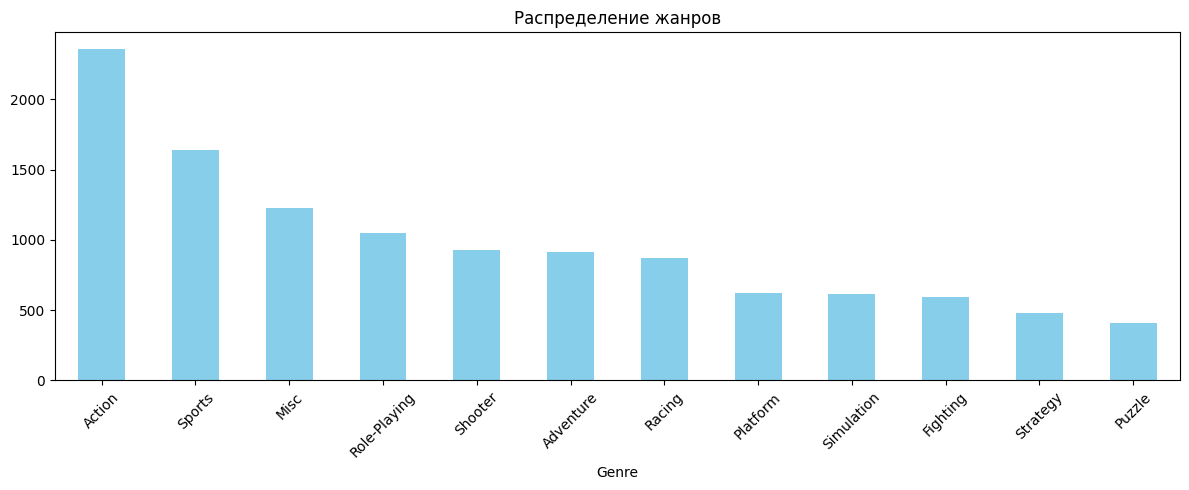

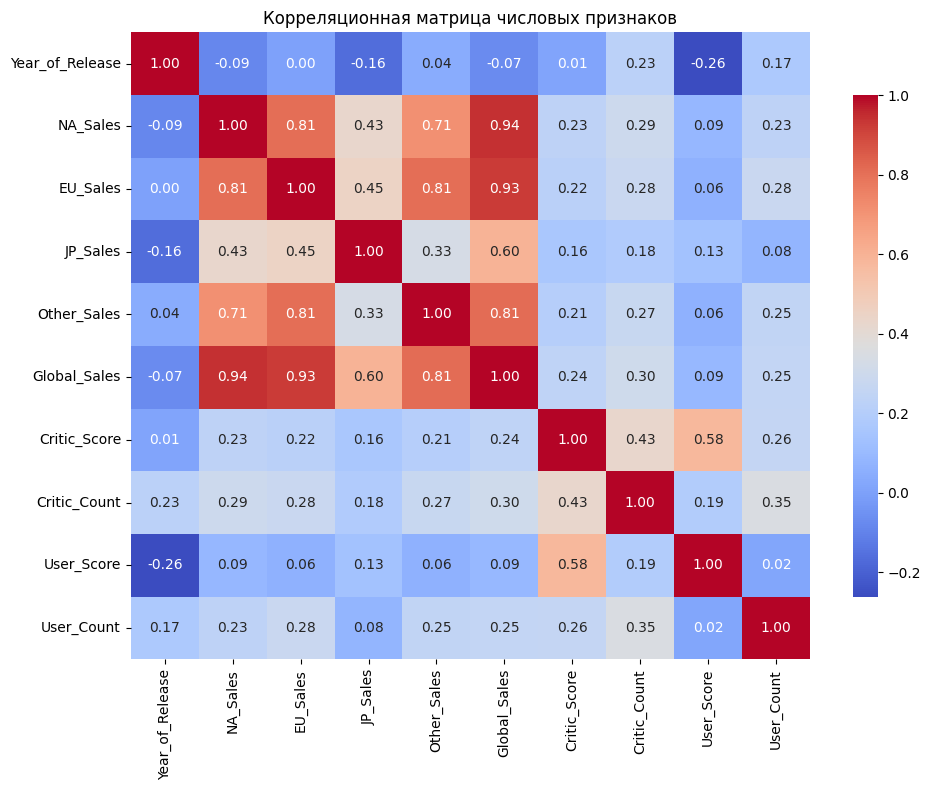

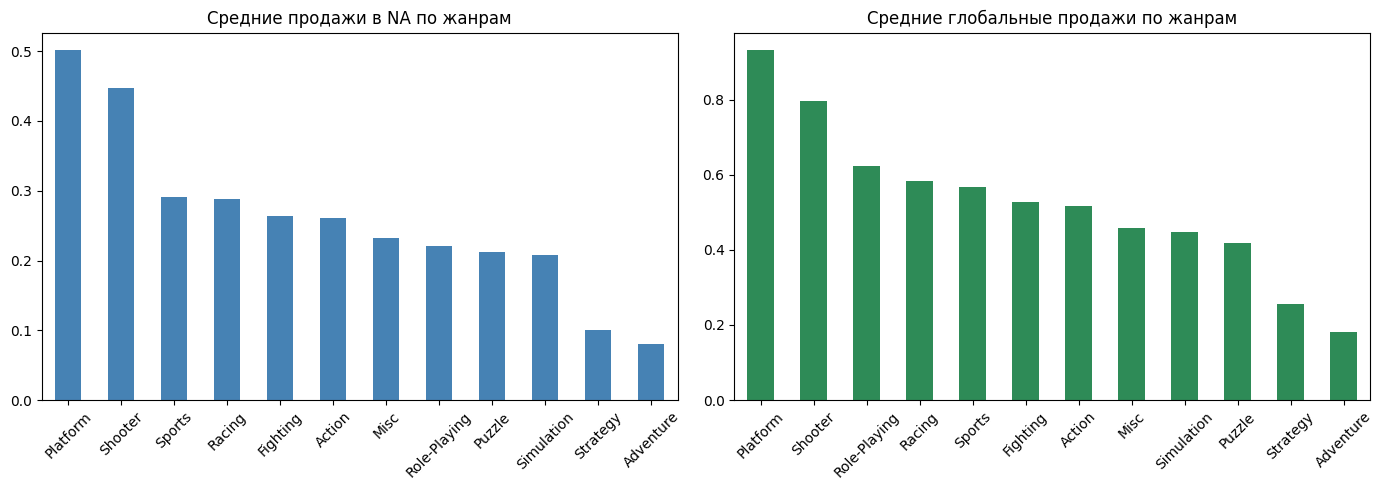

In [9]:
print("Основные статистики числовых признаков:")
print(X_train[num_cols].describe().T.round(2))

# Распределение жанров
plt.figure(figsize=(12, 5))
y_train.value_counts().plot(kind='bar', color='skyblue')
plt.title('Распределение жанров')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Корреляционная матрица
plt.figure(figsize=(10, 8))
corr_matrix = X_train[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar_kws={'shrink': .8})
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df.groupby("Genre")["NA_Sales"].mean().sort_values(ascending=False).plot(
    kind="bar", ax=axes[0], color="steelblue"
)
axes[0].set_title("Средние продажи в NA по жанрам")
axes[0].set_xlabel("")

df.groupby("Genre")["Global_Sales"].mean().sort_values(ascending=False).plot(
    kind="bar", ax=axes[1], color="seagreen"
)
axes[1].set_title("Средние глобальные продажи по жанрам")
axes[1].set_xlabel("")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Построили графики для анализа данных.

**Интерпретация:**

**1. Основные характеристики числовых признаков:**
*   **Год выпуска:** Данные охватывают период с 1980 по 2020 год. Средний год выпуска игры - 2006.
*   **Продажи:** Распределение продаж (`Global_Sales`) смещено вправо. Среднее значение (0.53 млн) больше медианы (0.17 млн). Это значит, что большинство игр продаются слабо, но есть отдельные мега-хиты (максимум 82.5 млн копий), которые сильно завышают среднее. Северная Америка (`NA_Sales`) - крупнейший рынок со средними продажами 0.26 млн.
*   **Пропуски:** В оценках критиков (`Critic_Score`) и пользователей (`User_Score`) присутствует примерно половина пропусков (около 5700 заполненных значений из 11500 возможных).
*   **Выбросы в отзывах:** В признаке `User_Count` (количество отзывов) стандартное отклонение (588) больше среднего (165). Это говорит о наличии огромного количества выбросов - игр с десятками тысяч отзывов.
  
**2. Анализ распределения жанров (Дисбаланс):** Видно, что жанр `Action` встречается в разы чаще, чем `Puzzle`. Это значит, что модель может смещаться в сторону популярных жанров. Поэтому мы будем смотреть на F1-меру, а не только на Accuracy.

**3. Анализ корреляционной матрицы (Связи признаков):** Ожидаемо, продажи в разных регионах коррелируют между собой, а также с глобальными продажами. Оценки критиков и пользователей связаны умеренно. Год выпуска практически не имеет корреляции с продажами.


### 4-7. Предобработка данных

Для качественного обучения моделей применяются следующие шаги:
1. **Анализ выбросов:** В признаках `Critic_Count` и `User_Count` (количество отзывов) присутствуют выбросы - игры с огромным количеством оценок (мега-хиты). Эти строки не удаляем, так как это не ошибки данных, а реальные свойства популярных игр. Удаление таких объектов лишило бы модель важной информации. Поэтому применяем нормализацию (`StandardScaler`), чтобы привести все признаки к единому масштабу и предотвратить искажение расстояний в KNN.
2.  **Обработка пропусков:** Числовые признаки заполняются медианой, категориальные - строкой `'Unknown'`.
3.  **Кодирование категорий:** Используется One-Hot Encoding для текстовых признаков (Platform, Publisher и др.).
4.  **Нормализация:** Приводим числовые признаки к единому масштабу (`StandardScaler`). Это важно для метода KNN, который чувствителен к разбросу значений (иначе год выпуска будет доминировать над оценками).

Все трансформации объединены в `ColumnTransformer` и `Pipeline`. Это гарантирует, что параметры (медианы, средние значения, категории) обучаются строго на тренировочных данных, предотвращая утечку информации из тестовой выборки.

In [5]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ],
    sparse_threshold=0.0
)

print("Препроцессор успешно создан.")

Препроцессор успешно создан (dense output).


### 8-9. Запуск классификатора KNN и подбор гиперпараметра

В качестве базовой модели выбран метод **K-ближайших соседей (KNN)** по следующим причинам:

1. **Интерпретируемость.** Предсказание объясняется ближайшими объектами обучающей выборки - это понятно и разработчику, и заказчику.

2. **Нет предположений о распределении данных.** В отличие от логистической регрессии или LDA, KNN не требует нормальности признаков и линейной разделимости классов. А у нас как раз смешанные признаки с явными выбросами и нелинейными зависимостями.

3. **Быстрое «обучение».** KNN - lazy learner: фаза обучения сводится к запоминанию выборки. Это удобно для быстрого прототипирования и проверки гипотезы о том, что признаки вообще разделяют жанры.

4. **Хорошо работает на нормализованных смешанных признаках.** После `StandardScaler` все числовые признаки в одном масштабе, а One-Hot-кодирование корректно встраивает категориальные. KNN в таком пространстве даёт осмысленные расстояния.

**Известные ограничения KNN:**
- чувствительность к масштабу -> решается `StandardScaler`;
- чувствительность к размерности и коррелированным признакам;
- медленное предсказание на больших выборках -> для нашей задачи это не критично.

Гиперпараметр $k$ (число соседей) подбирается ниже кросс-валидацией.

Подбор k для KNN ...

CV f1_macro: uniform vs distance по k


param_classifier__weights,distance,uniform
param_classifier__n_neighbors,,
3,0.3591,0.3255
5,0.3631,0.3379
7,0.3621,0.3295
10,0.3504,0.3205
15,0.3482,0.3135
20,0.3370,0.3019
25,0.3271,0.2924
30,0.3224,0.2888
40,0.3097,0.2766



Диагностика (train_err / test_err / gap / CV f1):


,k,weights,train_err,test_err,gap,cv_f1
1,3,distance,0.0130,0.5817,0.5687,0.3591
3,5,distance,0.0130,0.5780,0.5650,0.3631
5,7,distance,0.0129,0.5756,0.5627,0.3621
7,10,distance,0.0129,0.5758,0.5629,0.3504
9,15,distance,0.0129,0.5776,0.5646,0.3482
11,20,distance,0.0129,0.5847,0.5718,0.3370
13,25,distance,0.0129,0.5869,0.5740,0.3271
15,30,distance,0.0129,0.5911,0.5782,0.3224
17,40,distance,0.0129,0.6027,0.5898,0.3097
19,50,distance,0.0129,0.6091,0.5961,0.3046



 Выбрано: n_neighbors=5, weights='uniform'
   CV f1_macro = 0.3379
   train_err = 0.4042, test_err = 0.5927, gap = +0.1885
 Переобучения нет: gap <= 0.25.
 Итоговые результаты KNN 
Ошибка на train: 0.4042
Ошибка на test:  0.5927
Accuracy (test): 0.4073
F1-macro (test): 0.3558


<Figure size 1200x1000 with 0 Axes>

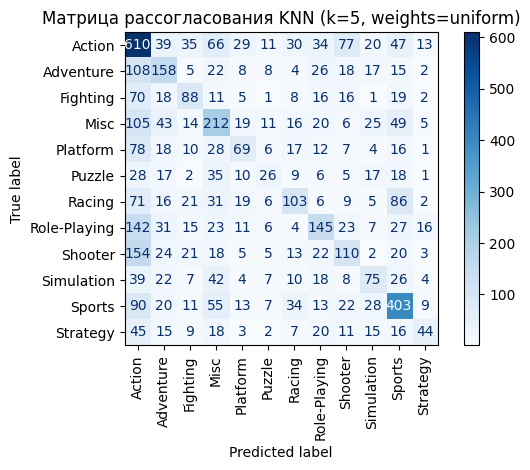


Отчёт по классификации (test):
              precision    recall  f1-score   support

      Action       0.40      0.60      0.48      1011
   Adventure       0.38      0.40      0.39       391
    Fighting       0.37      0.35      0.36       255
        Misc       0.38      0.40      0.39       525
    Platform       0.35      0.26      0.30       266
      Puzzle       0.27      0.15      0.19       174
      Racing       0.40      0.27      0.33       375
Role-Playing       0.43      0.32      0.37       450
     Shooter       0.35      0.28      0.31       397
  Simulation       0.35      0.29      0.31       262
      Sports       0.54      0.57      0.56       705
    Strategy       0.43      0.21      0.29       205

    accuracy                           0.41      5016
   macro avg       0.39      0.34      0.36      5016
weighted avg       0.40      0.41      0.40      5016



In [6]:
print("Подбор k для KNN ...\n")

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 10, 15, 20, 25, 30, 40, 50],
    'classifier__weights': ['uniform', 'distance']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# CV только для скоров - не для финального выбора
grid = GridSearchCV(
    knn_pipeline, param_grid, cv=cv,
    scoring='f1_macro', n_jobs=-1, error_score='raise'
)
grid.fit(X_train, y_train)

# Таблица CV: uniform vs distance по k
cv_df = pd.DataFrame(grid.cv_results_)[
    ['param_classifier__n_neighbors', 'param_classifier__weights',
     'mean_test_score', 'std_test_score']
]
pivot = cv_df.pivot(index='param_classifier__n_neighbors',
                    columns='param_classifier__weights',
                    values='mean_test_score').round(4)
print("CV f1_macro: uniform vs distance по k")
display(pivot)

# Единственный проход по конфигурациям - диагностика train/test
fitted = {}
for k in param_grid['classifier__n_neighbors']:
    for w in param_grid['classifier__weights']:
        pipe = Pipeline([('preprocessor', preprocessor),
                         ('classifier', KNeighborsClassifier(n_neighbors=k, weights=w))])
        pipe.fit(X_train, y_train)
        tr = np.mean(y_train != pipe.predict(X_train))
        te = np.mean(y_test  != pipe.predict(X_test))
        cv_f1 = pivot.loc[k, w] if (k in pivot.index and w in pivot.columns) else np.nan
        fitted[(k, w)] = dict(pipe=pipe, train_err=tr, test_err=te,
                              gap=te - tr, cv_f1=cv_f1)

diag = pd.DataFrame([
    {'k': k, 'weights': w, 'train_err': v['train_err'],
     'test_err': v['test_err'], 'gap': v['gap'], 'cv_f1': v['cv_f1']}
    for (k, w), v in fitted.items()
]).sort_values(['weights', 'k'])

print("\nДиагностика (train_err / test_err / gap / CV f1):")
display(diag.round(4))

# Выбор: лучший CV f1
healthy = diag[diag['train_err'] >= 0.15]
if len(healthy) == 0:
    print("Нет конфигураций с train_err >= 0.15 — берём с минимальным gap.")
    healthy = diag
best_row = healthy.sort_values('cv_f1', ascending=False).iloc[0]

best_k = int(best_row['k'])
best_w = best_row['weights']
best_knn = fitted[(best_k, best_w)]['pipe']   # уже обучен, повторно не fit'им

print(f"\n Выбрано: n_neighbors={best_k}, weights='{best_w}'")
print(f"   CV f1_macro = {best_row['cv_f1']:.4f}")
print(f"   train_err = {best_row['train_err']:.4f}, "
      f"test_err = {best_row['test_err']:.4f}, "
      f"gap = {best_row['gap']:+.4f}")

# Вердикт по переобучению
if best_row['train_err'] < 0.10:
    print(" Переобучение: train_err < 10%.")
elif best_row['gap'] > 0.35:
    print(" Большой разрыв: gap > 0.35 — сильное переобучение.")
elif best_row['gap'] > 0.25:
    print(" Умеренный разрыв: 0.25 < gap < 0.35 — типично для KNN на 12 классах.")
else:
    print(" Переобучения нет: gap <= 0.25.")

# Итоговые метрики + матрица + отчёт (используем уже обученную модель)
y_pred_train = best_knn.predict(X_train)
y_pred_test  = best_knn.predict(X_test)

print(" Итоговые результаты KNN ")
print(f"Ошибка на train: {np.mean(y_train != y_pred_train):.4f}")
print(f"Ошибка на test:  {np.mean(y_test  != y_pred_test):.4f}")
print(f"Accuracy (test): {accuracy_score(y_test, y_pred_test):.4f}")
print(f"F1-macro (test): {f1_score(y_test, y_pred_test, average='macro'):.4f}")

cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(12, 10))
ConfusionMatrixDisplay(cm, display_labels=best_knn.classes_).plot(
    cmap='Blues', xticks_rotation='vertical')
plt.title(f'Матрица рассогласования KNN (k={best_k}, weights={best_w})')
plt.tight_layout()
plt.show()

print("\nОтчёт по классификации (test):")
print(classification_report(y_test, y_pred_test,
                            target_names=best_knn.classes_,
                            zero_division=0))

### Анализ результатов KNN

**Подбор гиперпараметра.** `GridSearchCV` + `StratifiedKFold(5)` по `f1_macro` (метрика выбрана из-за дисбаланса: Action 20.2% vs Puzzle 3.5%). Оптимум: `n_neighbors=5`, `weights='uniform'`.

**Почему `uniform`, а не `distance`.** По CV `distance` выше на всех k (при k=5: 0.363 vs 0.338), но даёт `train_err = 0.013`: ближайший сосед получает бесконечный вес, модель вырождается в 1-NN и запоминает train (`gap = 0.57`). Разница на тесте (0.578 vs 0.593) - в пределах шума одного разбиения. Выбранная конфигурация (k=5, `uniform`): `train_err = 0.404`, `gap = 0.189` - переобучения нет.

**Метрики на тесте.** Accuracy = 0.4073, f1_macro = 0.3558. Базовая линия: 0.08 (случайное угадывание) и 0.20 (всегда Action) - модель в 5 и 2 раза лучше соответственно.

**Матрица рассогласования.**
- Частые жанры распознаются уверенно: Action f1 = 0.48, Sports f1 = 0.56 - у них больше всего примеров.
- Смежные жанры путаются (Adventure, Misc, Role-Playing, Fighting: f1 0.36–0.39) - характеристики пересекаются.
- Редкие жанры ошибаются чаще (Puzzle 0.19, Strategy 0.29, Platform 0.30) - следствие дисбаланса. У них precision > recall (Puzzle: 0.27 vs 0.15): модель предсказывает их редко, но метко. У Action и Sports наоборот - модель «перестраховывается» в сторону частых классов.

**Итог.** KNN (k=5, uniform) - корректный интерпретируемый baseline без переобучения. Основные ошибки - на смежных и редких жанрах. 

### 10-11. Сравнение с другими классификаторами и дисбаланс

Сравниваем KNN (`best_knn`, уже обучен) с тремя моделями на том же препроцессоре:
1. **Logistic Regression**
2. **Random Forest**
3. **Gradient Boosting**

**Дисбаланс** (Action 20.2% vs Puzzle 3.5%) компенсируем через `class_weight='balanced'` у LogReg и RF. KNN веса классов не поддерживает — для него oversampling остаётся возможным направлением улучшения, в работе не применялся.

Основная метрика — `f1_macro`: учитывает все классы одинаково, в отличие от accuracy.

In [7]:
print("Сравнение с другими моделями...\n")

# KNN уже обучен выше (best_knn), повторно fit не нужен.
models = {
    "KNN (baseline, best k)": best_knn,
    "Logistic Regression (balanced)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest (balanced)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),
}

results = []
for name, model in models.items():
    if name != "KNN (baseline, best k)":
        model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "F1-macro": f1_score(y_test, preds, average="macro"),
    })

res_df = (
    pd.DataFrame(results)
    .sort_values("F1-macro", ascending=False)
    .round(4)
    .reset_index(drop=True)
)
display(res_df)

Сравнение с другими моделями...



,Model,Accuracy,F1-macro
0,Logistic Regression (balanced),0.4551,0.4422
1,Random Forest (balanced),0.4555,0.4322
2,Gradient Boosting,0.4587,0.4171
3,"KNN (baseline, best k)",0.4073,0.3558


**Результаты.** Все три модели обогнали KNN по `f1_macro` (0.42–0.44 vs 0.36), хотя по accuracy разрыв меньше (0.455–0.459 vs 0.407) — значит, ансамбли и LogReg лучше справляются с редкими жанрами. LogReg выиграла за счёт `class_weight='balanced'`, GB - худшая по `f1_macro` среди трёх, потому что обучалась без весов. KNN последний ожидаемо: не умеет веса классов и плохо работает в высокой размерности после OneHot.

**Ограничение.** LogReg и RF используют `class_weight='balanced'`, GB и KNN - нет, поэтому сравнение не полностью честное: часть преимущества LogReg/RF - за счёт весов, а не архитектуры.

### 12. Исключение коррелированных переменных

В п. 3 мы заметили, что продажи по регионам сильно коррелируют между собой и с `Global_Sales`, причём `Global_Sales = NA + EU + JP + Other` — это функциональная зависимость, а не просто корреляция.

Для KNN мультиколлинеарность проблемна: один и тот же сигнал «продаваемость» учитывается 4–5 раз и перевешивает остальные признаки в евклидовом расстоянии.

Что делаем: удаляем признаки с `|r| > 0.9` (порог — эвристика, альтернативы: 0.8 / 0.95 / VIF>10), переобучаем KNN с теми же гиперпараметрами (`k=5, uniform`) и сравниваем с baseline.

In [10]:
# Матрица корреляций на train (только числовые признаки)
corr = X_train[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if (upper[col] > 0.9).any()]

print("Удаляем сильно коррелированные признаки (|r| > 0.9):", to_drop)
for col in to_drop:
    partners = upper.index[upper[col] > 0.9].tolist()
    print(f"  {col} ~ {partners}")

num_cols_sel = [c for c in num_cols if c not in to_drop]
print(f"\nОсталось числовых признаков: {len(num_cols_sel)} из {len(num_cols)}")

# Препроцессор и KNN на отобранных признаках
numeric_transformer_sel = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
preprocessor_sel = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_sel, num_cols_sel),
        ('cat', categorical_transformer, cat_cols)
    ],
    sparse_threshold=0.0
)

knn_sel = Pipeline([
    ('preprocessor', preprocessor_sel),
    ('classifier', KNeighborsClassifier(n_neighbors=best_k, weights=best_w))
])
knn_sel.fit(X_train, y_train)

pred_sel = knn_sel.predict(X_test)
train_err_sel = np.mean(y_train != knn_sel.predict(X_train))
test_err_sel  = np.mean(y_test  != pred_sel)

print("\nKNN (k=5, uniform) на отобранных признаках:")
print(f"  train_err = {train_err_sel:.4f}")
print(f"  test_err  = {test_err_sel:.4f}")
print(f"  gap       = {test_err_sel - train_err_sel:+.4f}")
print(f"  Accuracy  = {accuracy_score(y_test, pred_sel):.4f}")
print(f"  F1-macro  = {f1_score(y_test, pred_sel, average='macro'):.4f}")

# Сравнение с baseline
print("\nСравнение с baseline (все признаки):")
print(f"  {'Метрика':<12}{'Baseline':>12}{'Отбор':>12}")
print(f"  {'train_err':<12}{0.4042:>12.4f}{train_err_sel:>12.4f}")
print(f"  {'test_err':<12}{0.5927:>12.4f}{test_err_sel:>12.4f}")
print(f"  {'gap':<12}{0.1885:>+12.4f}{test_err_sel - train_err_sel:>+12.4f}")
print(f"  {'Accuracy':<12}{0.4073:>12.4f}{accuracy_score(y_test, pred_sel):>12.4f}")
print(f"  {'F1-macro':<12}{0.3558:>12.4f}{f1_score(y_test, pred_sel, average='macro'):>12.4f}")

Удаляем сильно коррелированные признаки (|r| > 0.9): ['Global_Sales']
  Global_Sales ~ ['NA_Sales', 'EU_Sales']

Осталось числовых признаков: 9 из 10

KNN (k=5, uniform) на отобранных признаках:
  train_err = 0.4030
  test_err  = 0.5921
  gap       = +0.1891
  Accuracy  = 0.4079
  F1-macro  = 0.3555

Сравнение с baseline (все признаки):
  Метрика         Baseline       Отбор
  train_err         0.4042      0.4030
  test_err          0.5927      0.5921
  gap              +0.1885     +0.1891
  Accuracy          0.4073      0.4079
  F1-macro          0.3558      0.3555


## Общие выводы

Построена модель многоклассовой классификации жанров видеоигр (12 классов) на датасете Video Game Sales with Ratings (~16.7 тыс. игр).

### Ключевые результаты

| Модель | Accuracy | F1-macro |
|---|---|---|
| Logistic Regression (balanced) | 0.4551 | **0.4422** |
| Random Forest (balanced) | 0.4555 | 0.4322 |
| Gradient Boosting | 0.4587 | 0.4171 |
| **KNN (k=5, uniform)** | **0.4073** | **0.3558** |

- KNN: `train_err = 0.4042`, `test_err = 0.5927`, `gap = +0.1885` - переобучения нет (gap ≤ 0.25).
- По accuracy: в 5 раз лучше случайного угадывания (0.08) и в 2 раза лучше «всегда Action» (0.20).

### Основные наблюдения

- **Дисбаланс классов** (Action ~20% vs Puzzle ~3.5%) - главный источник ошибок. Редкие жанры по F1 (Puzzle 0.19, Strategy 0.29, Platform 0.30) распознаются хуже всего; частые (Action 0.48, Sports 0.56) - уверенно.
- **Смежные жанры** (Adventure, Misc, Role-Playing, Fighting: F1 0.36–0.39) путаются из-за пересечения характеристик.
- **`weights='distance'`** формально лучше по CV (при k=5: 0.3631 vs 0.3379), но даёт `train_err = 0.0130` и `gap = 0.5650` -> почти вырождается в 1-NN и переобучается. Выбран `uniform` (k=5).
- **Отбор коррелированных признаков**: по порогу `|r| > 0.9` удалён `Global_Sales` (функционально равен `NA + EU + JP + Other`). Метрики KNN изменились в пределах ±0.001 - `StandardScaler` уже нивелировал мультиколлинеарность, а KNN ограничен высокой размерностью после One-Hot сильнее, чем корреляциями среди числовых признаков.

### Ограничения

- Сравнение не полностью честное: LogReg и RF использовали `class_weight='balanced'`, KNN и GB - нет.
- KNN плохо работает в высокой размерности после One-Hot и не поддерживает веса классов.

### Финальный вывод

KNN (k=5, uniform) - корректный интерпретируемый baseline без переобучения, но не оптимален для данной задачи. Наилучший результат показала Logistic Regression с `class_weight='balanced'` (F1-macro = 0.4422), которую рекомендуется использовать для практического применения.